In [1]:
###Convert Energy Rate to MWh

import pandas as pd

# Input and output paths
input_path = r"E:\2nd_Main Paper\code and fig\Fig 2\CA\Data\2024CaliforniaMovesData_sorted_above_Energy Rate.csv"
output_path = r"E:\2nd_Main Paper\code and fig\Fig 2\CA\Data\2024CaliforniaMovesData_sorted_above_Energy Rate_MWh.csv"

# Read CSV
df = pd.read_csv(input_path)

# Divide the specified columns by 3,600,000 if they exist
for col in ["Energy Rate", "Predicted Energy Rate"]:
    if col in df.columns:
        df[col] = df[col] / 3_600_000

# Save the updated dataframe to output CSV
df.to_csv(output_path, index=False)

print(f"File saved to: {output_path}")


File saved to: E:\2nd_Main Paper\code and fig\Fig 2\CA\Data\2024CaliforniaMovesData_sorted_above_Energy Rate_MWh.csv


Plotted data for: Passenger Car - Gasoline
Plotted data for: Passenger Car - Ethanol (E-85)
Plotted data for: Light Commercial Truck - Gasoline
Plotted data for: Passenger Truck - Gasoline
Plotted data for: Motorcycle - Gasoline
Plotted data for: Passenger Car - Diesel Fuel
Plotted data for: Single Unit Short-haul Truck - Diesel Fuel
Plotted data for: Passenger Truck - Ethanol (E-85)
Plotted data for: Combination Long-haul Truck - Diesel Fuel
Plotted data for: Single Unit Short-haul Truck - Gasoline
Plotted data for: Light Commercial Truck - Ethanol (E-85)
Plotted data for: Passenger Car - Electricity


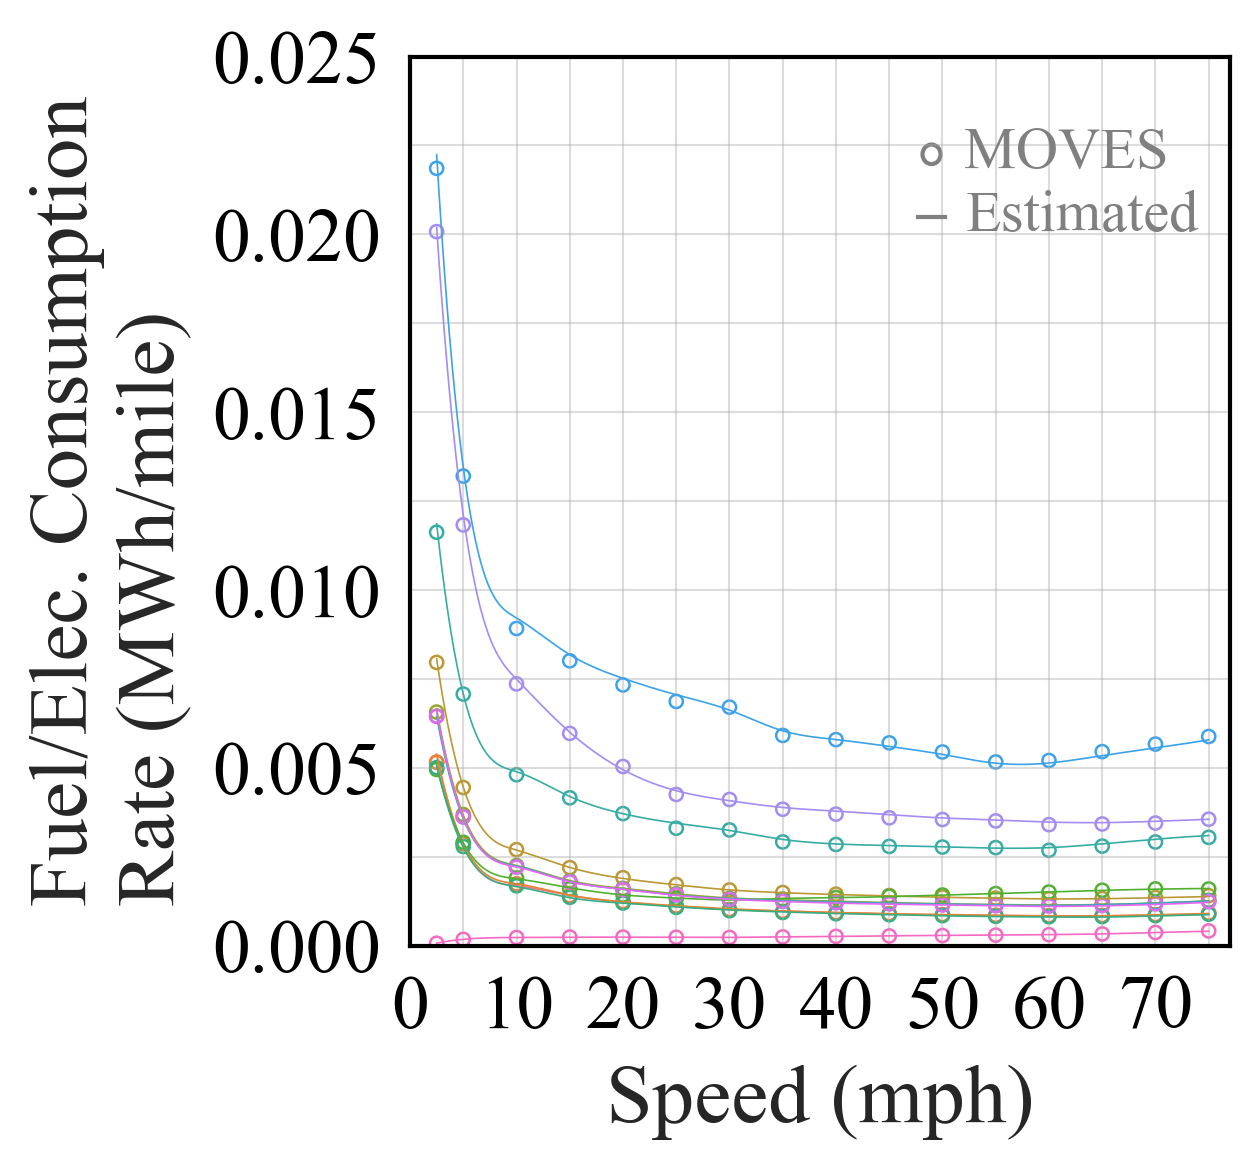

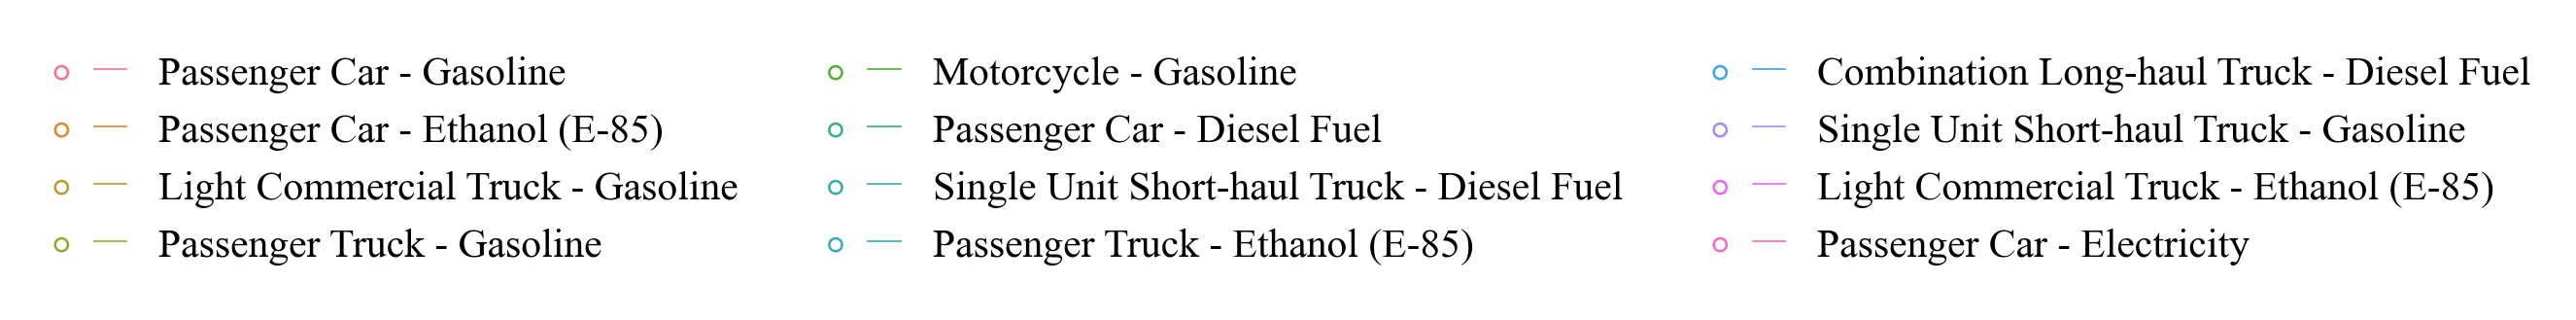

Y-axis maximum (Energy Rate + Predicted Energy Rate) for Age 2 groups: 0.0222390451388888


In [2]:
# ----------------------------- Working Energy Rate -----------------------------
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.interpolate import make_interp_spline
import numpy as np
from matplotlib.patches import Circle
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerTuple
from matplotlib.ticker import AutoMinorLocator

# ----------------------------- Load -----------------------------
file_path = r"E:\2nd_Main Paper\code and fig\Fig 2\CA\Data\2024CaliforniaMovesData_sorted_above_Energy Rate_MWh.csv"
data = pd.read_csv(file_path)

# ----------------------------- Typography -----------------------------
plt.rcParams.update({
    'text.usetex': False,
    'font.family': 'Times New Roman',
    'mathtext.fontset': 'custom',
    'mathtext.rm': 'Times New Roman',
    'mathtext.it': 'Times New Roman:italic',
    'mathtext.bf': 'Times New Roman:bold'
})

# ----------------------------- Utils -----------------------------
def add_manual_symbol_annotation(ax):
    # Circle (MOVES)
    circle_x, circle_y = 0.636, 0.89
    circle_radius = 0.011
    circle_text_gap_x = 0.04

    circle = Circle(
        (circle_x, circle_y),
        circle_radius,
        transform=ax.transAxes,
        fill=False,
        edgecolor='gray',
        linewidth=1
    )
    ax.add_patch(circle)
    ax.annotate(
        'MOVES',
        xy=(circle_x + circle_text_gap_x, circle_y),
        xycoords='axes fraction',
        fontsize=14,
        color='gray',
        va='center',
        ha='left'
    )

    # Line (Estimated)
    line_x_start, line_x_end = 0.620, 0.653
    line_y = 0.82
    line_text_gap_x = 0.025
    ax.add_line(Line2D(
        [line_x_start, line_x_end],
        [line_y, line_y],
        transform=ax.transAxes,
        color='gray',
        linewidth=1
    ))
    ax.annotate(
        'Estimated',
        xy=(line_x_end + line_text_gap_x, line_y),
        xycoords='axes fraction',
        fontsize=14,
        color='gray',
        va='center',
        ha='left'
    )

def configure_axes(ax, y_values,
                   xlabel_pad=5, ylabel_pad=5,
                   xlabel_size=20, ylabel_size=20,
                   xtick_size=18, ytick_size=18,
                   xlim=None, ylim=None, xticks=None, yticks=None):
    ax.set_xlabel('Speed (mph)', labelpad=xlabel_pad, fontsize=xlabel_size, color='black', alpha=0.85)
    ax.set_ylabel('Fuel/Elec. Consumption\nRate (MWh/mile)',
                  labelpad=ylabel_pad, fontsize=ylabel_size,
                  color='black', alpha=0.85, multialignment='left')

    # Apply limits/ticks ONLY if provided
    if xlim is not None:
        ax.set_xlim(xlim)
    if ylim is not None:
        ax.set_ylim(ylim)
    if xticks is not None:
        ax.set_xticks(xticks)
    if yticks is not None:
        ax.set_yticks(yticks)

    ax.tick_params(axis='x', labelsize=xtick_size)
    ax.tick_params(axis='y', labelsize=ytick_size)

    # Tick styling
    ax.tick_params(axis='both', which='both', color='white')
    for lbl in ax.get_xticklabels() + ax.get_yticklabels():
        lbl.set_color('black')
        lbl.set_alpha(0.9)
        lbl.set_fontsize(12)
        lbl.set_fontname('Times New Roman')

    # Border & facecolor
    ax.set_facecolor('white')
    ax.figure.set_facecolor('white')
    for spine in ax.spines.values():
        spine.set_edgecolor('black')
        spine.set_linewidth(1.0)
        spine.set_position(('outward', 0))

def create_legend_figure(scatter_lines, save_path=None, ncol=1, legend_fontsize=12, legend_figsize=(4, 4)):
    """Save a standalone legend image to exactly the path given."""
    fig, ax = plt.subplots(figsize=legend_figsize, dpi=300)
    ax.set_axis_off()

    handles, labels = [], []
    for scatter, line, label in scatter_lines:
        handles.append((scatter, line))
        labels.append(label)

    ax.legend(
        handles, labels,
        handler_map={tuple: HandlerTuple(ndivide=None)},
        fontsize=legend_fontsize,
        frameon=False,
        loc='center',
        ncol=ncol
    )

    ax.set_facecolor('white')
    ax.figure.set_facecolor('white')
    plt.tight_layout()

    # ----------------------------- Save legend in multiple formats -----------------------------
    if save_path:
        base_path = save_path.rsplit('.', 1)[0]  # remove extension if any
        fig.savefig(base_path + '.jpg', dpi=300, bbox_inches='tight')
        fig.savefig(base_path + '.svg', dpi=300, bbox_inches='tight')
        fig.savefig(base_path + '.pdf', dpi=300, bbox_inches='tight')

    plt.show()
    plt.close(fig)

# ----------------------------- Main plot -----------------------------
def plot_all_data_continuous_spline(
    vehicle_groups, age,
    xlabel_pad=5, ylabel_pad=5,
    xlabel_size=20, ylabel_size=20,
    xtick_size=18, ytick_size=18, annotation_size=16,
    xlim=None, ylim=None, xticks=None, yticks=None,   # <- centralized here
    main_save_path=None,
    legend_save_path=None,
    legend_ncol=1, legend_fontsize=12, legend_figsize=(4, 4)
):
    fig, ax = plt.subplots(figsize=(4.3, 4), dpi=300)  # Square figure
    colors = sns.color_palette("husl", len(vehicle_groups))
    scatter_lines = []
    all_y = []

    for idx, (vehicle_type, fuel_type) in enumerate(vehicle_groups):
        subset = data[(data['Age'] == age) &
                      (data['Vehicle Type'] == vehicle_type) &
                      (data['Fuel Type'] == fuel_type)]
        if not subset.empty:
            subset = subset.sort_values(by='Speed')

            # Drop rows where predicted values are missing
            subset = subset.dropna(subset=['Predicted Energy Rate'])
            if subset.empty:
                print(f'No valid predicted data for: {vehicle_type} - {fuel_type}')
                continue

            # Scatter (open circles)
            scatter = ax.scatter(
                subset['Speed'], subset['Energy Rate'],
                marker='o', facecolors='none', edgecolors=colors[idx],
                s=10, linewidth=0.6, alpha=1
            )

            # Spline line on Predicted Energy Rate
            x_new = np.linspace(subset['Speed'].min(), subset['Speed'].max(), 300)
            spline = make_interp_spline(subset['Speed'], subset['Predicted Energy Rate'], k=3)
            y_smooth = spline(x_new)

            ax.plot(x_new, y_smooth, linestyle='-', linewidth=0.4, alpha=1, color=colors[idx])

            proxy_line = Line2D([], [], color=colors[idx], linewidth=0.4)
            scatter_lines.append((scatter, proxy_line, f'{vehicle_type} - {fuel_type}'))

            all_y.extend(subset['Energy Rate'].dropna().tolist())
            all_y.extend(y_smooth.tolist())
            print(f'Plotted data for: {vehicle_type} - {fuel_type}')
        else:
            print(f'No data found for: {vehicle_type} - {fuel_type}')

    # Axes (all four controlled via args)
    configure_axes(ax, all_y, xlabel_pad, ylabel_pad,
                   xlabel_size, ylabel_size,
                   xtick_size, ytick_size,
                   xlim=xlim, ylim=ylim, xticks=xticks, yticks=yticks)

    # Annotations & grids
    add_manual_symbol_annotation(ax)
    ax.grid(True, color='darkgray', linestyle='-', linewidth=0.5, alpha=0.4)
    ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))
    ax.grid(which='minor', color='darkgray', linestyle='-', linewidth=0.5, alpha=0.4)

    plt.tight_layout()

    # ----------------------------- Save main plot in multiple formats -----------------------------
    if main_save_path:
        base_path = main_save_path.rsplit('.', 1)[0]  # remove extension if any
        fig.savefig(base_path + '.jpg', dpi=300, bbox_inches='tight')
        fig.savefig(base_path + '.svg', dpi=300, bbox_inches='tight')
        fig.savefig(base_path + '.pdf', dpi=300, bbox_inches='tight')

    plt.show()
    plt.close(fig)

    # Separate legend image (optional)
    if legend_save_path:
        create_legend_figure(
            scatter_lines,
            save_path=legend_save_path,
            ncol=legend_ncol,
            legend_fontsize=legend_fontsize,
            legend_figsize=legend_figsize
        )

# ----------------------------- Usage -----------------------------
vehicle_fuel_groups = [
    ('Passenger Car', 'Gasoline'),
    ('Passenger Car', 'Ethanol (E-85)'),
    ('Light Commercial Truck', 'Gasoline'),
    ('Passenger Truck', 'Gasoline'),
    ('Motorcycle', 'Gasoline'),
    ('Passenger Car', 'Diesel Fuel'),
    ('Single Unit Short-haul Truck', 'Diesel Fuel'),
    ('Passenger Truck', 'Ethanol (E-85)'),
    ('Combination Long-haul Truck', 'Diesel Fuel'),
    ('Single Unit Short-haul Truck', 'Gasoline'),
    ('Light Commercial Truck', 'Ethanol (E-85)'),
    ('Passenger Car', 'Electricity')
]

main_save_path = r"E:\2nd_Main Paper\code and fig\Fig 2\2_b_1"
legend_save_path = r"E:\2nd_Main Paper\code and fig\Fig 2\2_legend"

# ---- Single place to control axis limits and ticks ----
xlim_vals = (0, 77)
ylim_vals = (0, 0.025)
xticks_vals = [0, 10, 20, 30, 40, 50, 60, 70]
yticks_vals = [0.000, 0.005, 0.010, 0.015, 0.020, 0.025]

plot_all_data_continuous_spline(
    vehicle_fuel_groups, age=2,
    xlabel_pad=5, ylabel_pad=5,
    xlabel_size=20, ylabel_size=20,
    xtick_size=18, ytick_size=18,
    annotation_size=16,
    xlim=xlim_vals, ylim=ylim_vals,
    xticks=xticks_vals, yticks=yticks_vals,
    main_save_path=main_save_path,
    legend_save_path=legend_save_path,
    legend_ncol=3,
    legend_fontsize=10,
    legend_figsize=(6, 1.2)
)

# ----------------------------- Post-compute -----------------------------
subset = data[
    (data['Age'] == 2) &
    (data[['Vehicle Type', 'Fuel Type']].apply(tuple, axis=1).isin(vehicle_fuel_groups))
]
y_max = max(subset["Energy Rate"].max(), subset["Predicted Energy Rate"].max())
print("Y-axis maximum (Energy Rate + Predicted Energy Rate) for Age 2 groups:", y_max)
